# Comparación consolidada de recomendadores

Este notebook reúne los métodos ya desarrollados con el mismo conjunto de candidatos y las selecciones persistidas en los notebooks individuales. Ejecutar antes `user_based.ipynb`, `item_based.ipynb` y `funksvd.ipynb`.

`BaselineOnly` estima sesgos mediante un procedimiento ALS, pero no es la factorización para feedback implícito exigida por el enunciado. La comparación incorpora ahora ALS implícito, BPR y Content-Based con búsquedas reproducibles y selección por nDCG@10.

In [1]:
from pathlib import Path
import sys

for location in (Path.cwd(), *Path.cwd().parents):
    candidate = location if (location / 'tarea_01').is_dir() else location / 'recsys_tareas'
    if (candidate / 'tarea_01' / 'general_experiments.py').is_file():
        REPO_ROOT = candidate
        break
else:
    raise FileNotFoundError('No se encontró la raíz de recsys_tareas.')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from tarea_01.general_experiments import (
    load_selections, run_general, plot_general_metrics,
    plot_required_sensitivities, write_competition_preview,
)

TASK_DIR = REPO_ROOT / 'tarea_01'
DATASET_DIR = TASK_DIR / 'dataset'
RESULTS_DIR = TASK_DIR / 'informe_assets' / 'data'
FIGURES_DIR = TASK_DIR / 'informe_assets'
SEED = 42
N_NEGATIVES = 100
RUN_COMPETITION = False

## Configuraciones y protocolo

Los hiperparámetros de UserKNN, ItemKNN y FunkSVD se seleccionan por RMSE en validación y se leen de las tablas de sensibilidad. ALS y BPR comparan 20, 50 y 100 factores; ALS contrasta además regularización 0.01 y 0.1. Content-Based compara TF-IDF de ingredientes (`min_df` 1, 5 y 10) con los embeddings BERT entregados, usando perfiles binarios y ponderados por rating. Estas familias se seleccionan por nDCG@10 y MAP@10 actúa como desempate. Los resultados son de desarrollo y no representan un test independiente.

BestRated utiliza la media de rating de cada receta sin regularización, una limitación que debe discutirse. MostPopular cuenta todas las interacciones de entrenamiento. Random genera un score uniforme reproducible para cada par usuario–receta, independiente del orden de evaluación. ALS y BPR binarizan como positivas las interacciones con rating ≥ 4. Content-Based construye cada perfil únicamente con esas interacciones de entrenamiento y compara pesos unitarios con pesos 1 para rating 4 y 2 para rating 5. La semilla 42 y un hilo de CPU favorecen la reproducibilidad.

In [2]:
selections = load_selections(RESULTS_DIR)
pd.DataFrame(selections).T

,method,config_id,k_neighbors,min_k,similarity,random_state,status,RMSE,MAE,similarity_fit_seconds,...,ActualKMin,ActualKMax,FitSeconds,EvaluationSeconds,is_selected_ndcg,n_factors,n_epochs,lr_all,reg_all,biased
UserKNN,UserKNN,userknn_msd_k100,100,1,msd,42,ok,0.936621,0.506971,0.441344,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ItemKNN,ItemKNN,item_msd_k80_min1,80,1,msd,42,ok,0.910791,0.485202,NaN,...,1,80,0.000004,14.731448,False,NaN,NaN,NaN,NaN,NaN
FunkSVD,FunkSVD,funk_f20_lr0.003_reg0.05_bias1_e30_s42,NaN,NaN,NaN,42,ok,0.884058,0.481343,NaN,...,NaN,NaN,0.453036,7.580024,False,20,30,0.003,0.05,True


## Evaluación común

Los candidatos son todos los ratings de validación más hasta 100 no observados por usuario. Todos los métodos usan exactamente la misma huella de candidatos, la misma relevancia ≥ 4 y el mismo desempate independiente de relevancia. Estos resultados deben nombrarse «Top-10 con negativos muestreados».

Los scores se ordenan sin recorte, lo que evita que los modelos implícitos, de contenido o una predicción explícita superior a 5 pierdan orden al saturarse. Solo los predictores de rating reciben RMSE y MAE sobre ratings reales; esos errores no aplican a Random, MostPopular, ALS, BPR ni Content-Based. Los archivos de protocolo registran esta decisión.

In [3]:
comparison = run_general(dataset_dir=DATASET_DIR, output_dir=RESULTS_DIR,
                         seed=SEED, n_negatives=N_NEGATIVES)
metrics = comparison['metrics']
display(metrics[['method', 'RMSE', 'MAE', 'Precision@10', 'Recall@10', 'NDCG@10', 'MAP@10']])

Evaluating BaselineOnly...


Evaluating BestRated...


Evaluating MostPopular...


Evaluating Random...


Evaluating UserKNN...


...

Evaluating content_ingredients_df10_binary...


Evaluating content_ingredients_df10_rating_excess...


Evaluating content_bert_binary...


Evaluating content_bert_rating_excess...


,method,RMSE,MAE,Precision@10,Recall@10,NDCG@10,MAP@10
0,BaselineOnly,0.881827,0.485716,0.068845,0.131803,0.109714,0.054154
1,BestRated,0.920964,0.525547,0.035299,0.057010,0.046559,0.019680
2,MostPopular,NaN,NaN,0.170052,0.354472,0.315829,0.203283
3,Random,NaN,NaN,0.050011,0.093192,0.075236,0.034536
4,UserKNN,0.936621,0.506971,0.033979,0.063145,0.053926,0.025657
5,ItemKNN,0.910791,0.485202,0.035709,0.071254,0.057394,0.028215
6,FunkSVD,0.884058,0.481343,0.061489,0.115573,0.093230,0.043560
7,ALS,NaN,NaN,0.165725,0.344962,0.310997,0.199806
8,BPR,NaN,NaN,0.110704,0.222698,0.186478,0.103871
9,ContentBased,NaN,NaN,0.084013,0.165789,0.135426,0.069666


## Resultados y compensaciones

Las barras conservan los valores originales y muestran separadamente error de rating y calidad de ranking. El baseline de popularidad se resalta porque permite relacionar precisión con la concentración observada en el EDA. Seleccionar por RMSE no optimiza automáticamente nDCG ni MAP.

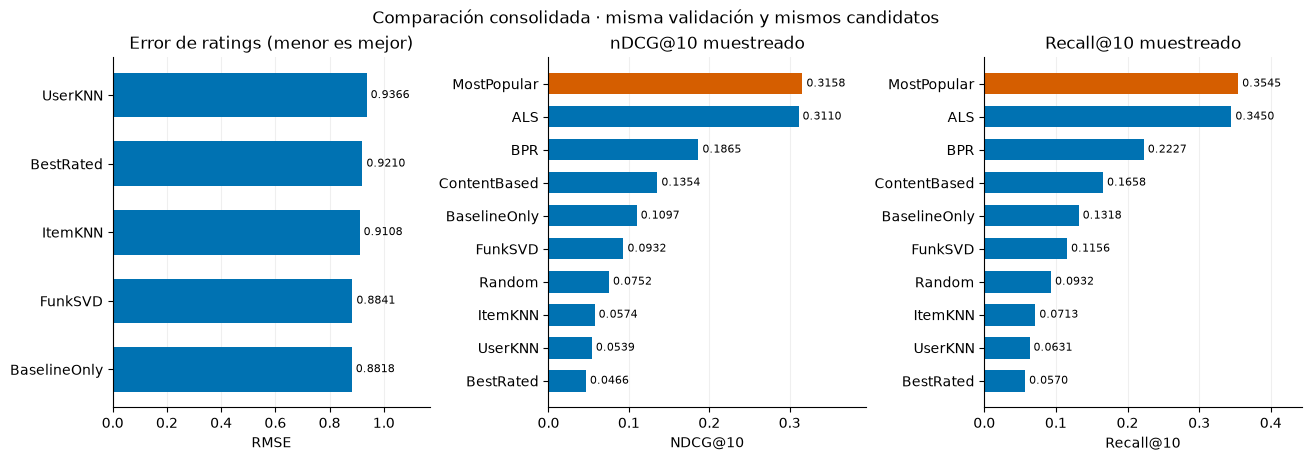

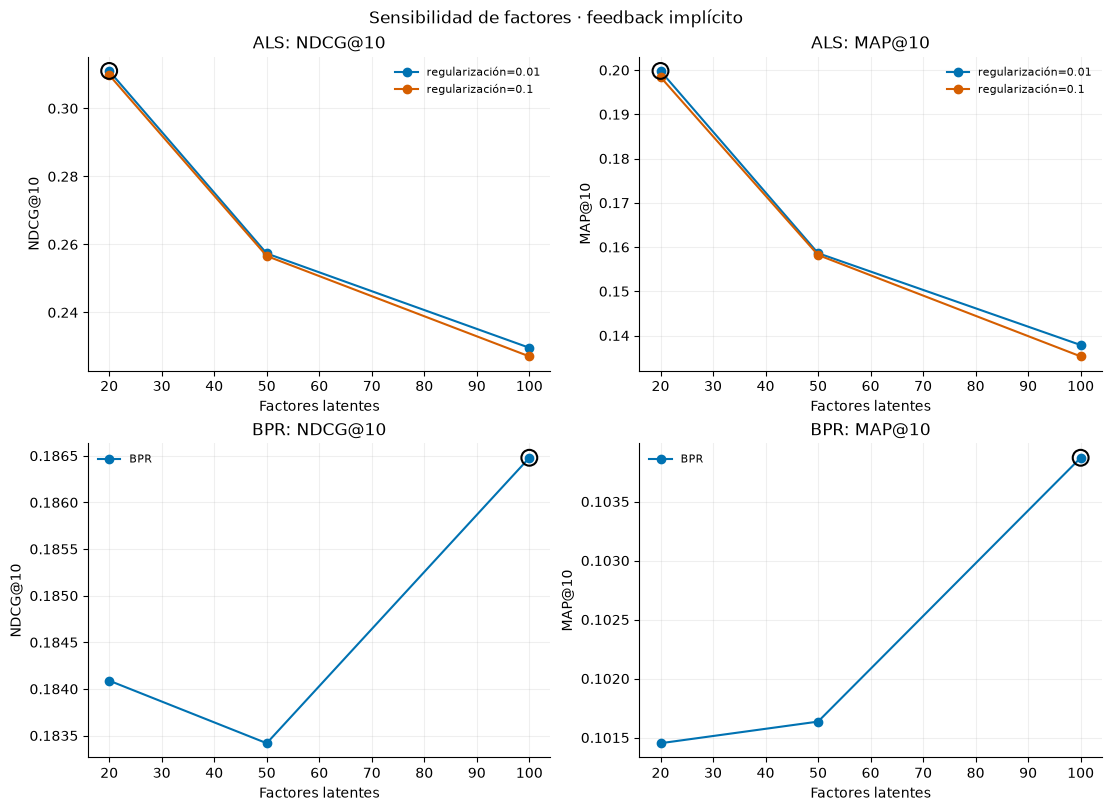

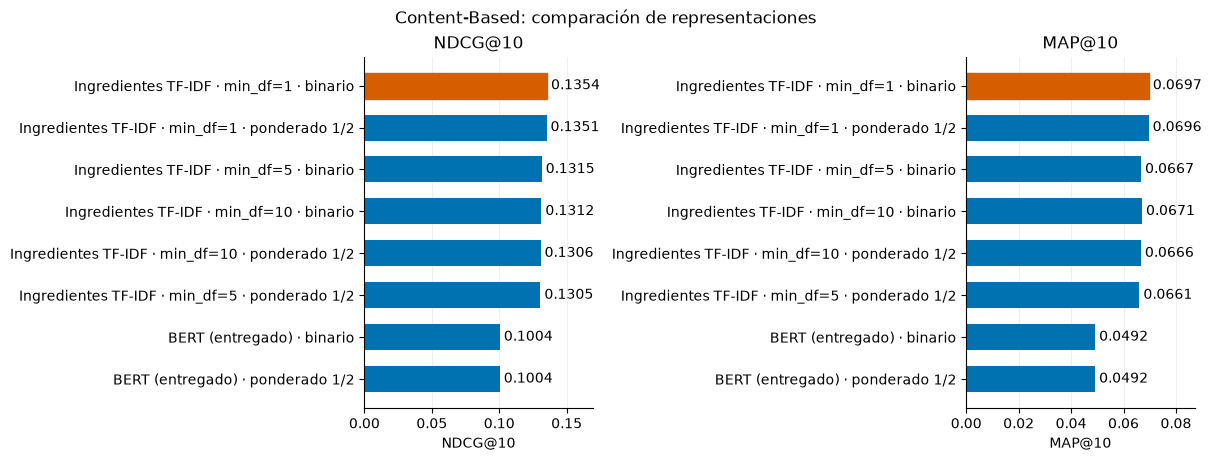

Menor RMSE observado: BaselineOnly (0.881827)
Mayor nDCG@10 observado: MostPopular (0.315829)


,difference_first_minus_second,ci95_low,ci95_high,users
NDCG@10,-0.004831,-0.011846,0.002272,4391
Recall@10,-0.00951,-0.018391,-0.000593,4391


In [4]:
fig = plot_general_metrics(metrics, FIGURES_DIR)
sensitivity_figures = plot_required_sensitivities(comparison['sensitivity'], FIGURES_DIR)
plt.show()
rating_best = metrics.loc[metrics['RMSE'].idxmin()]
ranking_best = metrics.loc[metrics['NDCG@10'].idxmax()]
print(f"Menor RMSE observado: {rating_best['method']} ({rating_best['RMSE']:.6f})")
print(f"Mayor nDCG@10 observado: {ranking_best['method']} ({ranking_best['NDCG@10']:.6f})")
display(pd.DataFrame(comparison['bootstrap']['metrics']).T[[
    'difference_first_minus_second', 'ci95_low', 'ci95_high', 'users'
]])

## Diversidad, novedad y cobertura

`InteractionILD` mide disimilitud coseno entre perfiles de interacción; `TagDiversity` cuenta tags distintos por lista y es un proxy amplio de diversidad, porque la metadata también contiene tags de tiempo o dieta. Para afirmar diversidad de estilos culinarios queda definir y justificar qué tags representan estilos.

`NoveltyBitsPerItem` es el promedio por recomendación de −log₂ p(i); `NoveltyBitsPerList` promedia la suma por lista, que corresponde a la normalización del enunciado. `CatalogCoverage` es la fracción del catálogo recomendada al menos una vez bajo estos candidatos muestreados. Las métricas por usuario permiten analizar compensaciones e incertidumbre sin mezclar escalas.

In [5]:
display(metrics[['method', 'InteractionILD', 'TagDiversity', 'NoveltyBitsPerItem',
                 'NoveltyBitsPerList', 'CatalogCoverage']])
comparison['evaluations']['MostPopular'].protocol

,method,InteractionILD,TagDiversity,NoveltyBitsPerItem,NoveltyBitsPerList,CatalogCoverage
0,BaselineOnly,0.983661,92.094659,12.813046,128.130456,0.172130
1,BestRated,0.982690,89.515664,13.460131,134.601309,0.173833
2,MostPopular,0.956724,91.983097,11.042289,110.422891,0.161629
3,Random,0.985642,91.505071,13.077239,130.772390,0.998013
4,UserKNN,0.988574,92.155961,13.385108,133.851075,0.668086
5,ItemKNN,0.986857,91.468785,13.285424,132.854241,0.967078
6,FunkSVD,0.984600,92.263917,12.914859,129.148591,0.344686
7,ALS,0.970182,90.386297,11.959722,119.597219,0.842628
8,BPR,0.979389,89.635339,12.902664,129.026643,0.971761
9,ContentBased,0.984199,80.218616,12.884390,128.843895,0.627785


{'protocol_version': 'validation-unseen-v2-raw-score-item-id-ties',
 'ranking_candidate_mode': 'negative_sample_100',
 'k': 10,
 'relevance_threshold': 4.0,
 'n_negatives': 100,
 'seed': 42,
 'sampler': 'numpy.default_rng; sorted users and catalog; without replacement',
 'tie_break': 'score descending, raw item ID ascending',
 'validation_items': 'all observed validation items, including ratings below threshold',
 'unobserved_relevance': 'unknown, treated as zero for offline ranking',
 'accuracy_population': 'macro mean over users with at least one relevant validation item',
 'beyond_accuracy_population': 'all evaluated users',
 'precision_denominator': 10,
 'map_denominator': 'min(k, number of relevant validation items)',
 'novelty_probability': 'training item observation count / training observation count',
 'interaction_ild': 'mean pairwise 1-cosine of binary training item-user vectors',
 'tag_diversity': 'mean distinct raw metadata tags in each recommendation list',
 'unknown_metad

## Alcance y cautelas

- Definir una taxonomía de estilos culinarios si se reportará diversidad de estilos.
- Confirmar conclusiones sobre catálogos completos o más candidatos y, para modelos estocásticos, varias semillas.
- Escribir las conclusiones del equipo con las cifras regeneradas; las cifras anteriores al cambio de desempate/recorte no son comparables directamente.

`informe_assets/data/all_methods_metrics.csv`, `all_methods_selection.json` y `all_methods_protocol.json` conservan la evidencia consolidada. Las sensibilidades de ALS, BPR y Content-Based quedan en archivos separados; cada método seleccionado exporta además predicciones y resultados por usuario.

## Generación optativa de archivos de competición

Por defecto esta sección no escribe archivos. Si se activa `RUN_COMPETITION`, se crean previsualizaciones en `results/competition_preview/`: se escoge el predictor de menor RMSE y el recomendador de mayor nDCG@10 de esta validación. Se puntúa el catálogo completo no visto para ranking, sin volver a buscar hiperparámetros. Los modelos mantienen el entrenamiento en `train.csv`; no se realiza envío externo.

In [6]:
if RUN_COMPETITION:
    preview_dir = write_competition_preview(comparison, dataset_dir=DATASET_DIR)
    print(f'Previsualizaciones guardadas en {preview_dir}')
else:
    print('RUN_COMPETITION=False: no se generaron archivos de competición.')

RUN_COMPETITION=False: no se generaron archivos de competición.
